In [1]:
import shutil
from pathlib import Path
import random
import math
from collections import defaultdict
from tqdm.notebook import tqdm  # Use tqdm.notebook for Jupyter
from datetime import datetime
import matplotlib.pyplot as plt
import numpy as np

# Set random seed for reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)

print("="*80)
print("RICE MOLD DETECTION - VALIDATION SET CREATION")
print("="*80)


RICE MOLD DETECTION - VALIDATION SET CREATION


Configuration

In [2]:
DATASET_ROOT = r"D:\Research\rice\balanced_augmented_dataset"

# Validation ratio (what % of training data to use for validation)
VAL_RATIO = 0.2  # 20% of training data

# Random seed for reproducibility
RANDOM_SEED = 42
# ======================================

print("\n📁 Configuration:")
print(f"   Dataset root: {DATASET_ROOT}")
print(f"   Validation ratio: {VAL_RATIO*100:.1f}% of training data")
print(f"   Random seed: {RANDOM_SEED}")

# Set seed
random.seed(RANDOM_SEED)

# Define paths
dataset_root = Path(DATASET_ROOT)
train_dir = dataset_root / 'train'
val_dir = dataset_root / 'val'
test_dir = dataset_root / 'test'

categories = ['healthy', 'early-risk', 'spoiled']



📁 Configuration:
   Dataset root: D:\Research\rice\balanced_augmented_dataset
   Validation ratio: 20.0% of training data
   Random seed: 42


Verifying Dataset Structure

In [3]:
print("\n" + "="*80)
print("STEP 1: VERIFYING DATASET STRUCTURE")
print("="*80)

issues = []

# Check if train directory exists
if not train_dir.exists():
    issues.append(f"❌ Training directory not found: {train_dir}")
    
# Check if test directory exists
if not test_dir.exists():
    issues.append(f"⚠️  Test directory not found: {test_dir}")

# Check if val directory already exists
if val_dir.exists():
    print(f"\n⚠️  Validation directory already exists: {val_dir}")
    response = input("   Do you want to overwrite it? (yes/no): ").lower()
    if response != 'yes':
        raise Exception("❌ User chose not to overwrite existing validation set")
    else:
        print("   Removing existing validation directory...")
        shutil.rmtree(val_dir)
        print("   ✓ Removed")

# Check categories in train
if train_dir.exists():
    found_categories = []
    for cat in categories:
        cat_path = train_dir / cat
        if cat_path.exists():
            found_categories.append(cat)
        else:
            issues.append(f"⚠️  Missing category in train: {cat}")
    
    if len(found_categories) == 0:
        issues.append(f"❌ No valid categories found in {train_dir}")

# Report issues
if any(issue.startswith("❌") for issue in issues):
    print("\n" + "="*80)
    print("ERRORS FOUND:")
    print("="*80)
    for issue in issues:
        print(f"  {issue}")
    print("\nExpected structure:")
    print(f"  {dataset_root.name}/")
    print(f"  ├── train/")
    print(f"  │   ├── healthy/")
    print(f"  │   ├── early-risk/")
    print(f"  │   └── spoiled/")
    print(f"  └── test/")
    print(f"      ├── healthy/")
    print(f"      ├── early-risk/")
    print(f"      └── spoiled/")
    raise Exception("Dataset structure verification failed")

if issues:
    print("\n⚠️  Warnings:")
    for issue in issues:
        if issue.startswith("⚠️"):
            print(f"  {issue}")

print("\n✅ Structure verification passed!")


STEP 1: VERIFYING DATASET STRUCTURE

✅ Structure verification passed!


Count Images Before Split

In [6]:
# ============================================================================
# CELL 4: Count Images Before Split (FIXED)
# ============================================================================
print("\n" + "="*80)
print("STEP 2: COUNTING IMAGES")
print("="*80)

def get_images(directory, category):
    """Get all images from a directory (fixed to avoid duplicates)."""
    cat_path = directory / category
    if not cat_path.exists():
        return []
    
    # Only glob once for each extension to avoid duplicates
    images = set()  # Use set to eliminate duplicates
    image_extensions = ['*.png', '*.jpg', '*.jpeg', '*.bmp']
    
    for ext in image_extensions:
        for img in cat_path.glob(ext):
            images.add(img)
    
    return sorted(list(images))  # Convert back to sorted list

# Count before split
stats_before = {}
print("\n📊 Current Training Set:")
for category in categories:
    train_imgs = get_images(train_dir, category)
    count = len(train_imgs)
    stats_before[category] = count
    print(f"   {category:12s}: {count:6,d} images")

total_before = sum(stats_before.values())
print(f"   {'TOTAL':12s}: {total_before:6,d} images")

# Debug: Show what file types were found
print("\n🔍 Debug - Sample files from each category:")
for category in categories:
    sample_files = get_images(train_dir, category)[:3]
    if sample_files:
        print(f"\n{category}:")
        for f in sample_files:
            print(f"   {f.name} (extension: {f.suffix})")


STEP 2: COUNTING IMAGES

📊 Current Training Set:
   healthy     :  3,500 images
   early-risk  :  3,500 images
   spoiled     :  3,500 images
   TOTAL       : 10,500 images

🔍 Debug - Sample files from each category:

healthy:
   Grainset_rice_2020-02-12-15-21-25_0_p600s.png (extension: .png)
   Grainset_rice_2020-02-12-18-18-42_2_p600s.png (extension: .png)
   Grainset_rice_2020-02-12-21-20-41_6_p600s.png (extension: .png)

early-risk:
   aug_00000_Grainset_rice_2020-08-24-09-29-26_5_p600s.png (extension: .png)
   aug_00001_Grainset_rice_2020-03-27-20-06-45_1_p600s.png (extension: .png)
   aug_00002_Grainset_rice_2021-08-06-19-41-19_2_p600s.png (extension: .png)

spoiled:
   aug_00000_Grainset_rice_2021-12-01-15-33-02_5_p600s.png (extension: .png)
   aug_00001_Grainset_rice_2020-03-07-23-52-37_5_p600s.png (extension: .png)
   aug_00002_Grainset_rice_2021-09-15-12-59-29_3_p600s.png (extension: .png)


Confirmation Prompt

In [7]:
print("\n" + "="*80)
print("CONFIRMATION")
print("="*80)
print(f"\nAbout to split training data:")
print(f"   - {int(total_before * (1 - VAL_RATIO)):,} images will remain in train/")
print(f"   - {int(total_before * VAL_RATIO):,} images will move to val/")
print(f"   - Test set will remain unchanged")

response = input("\nProceed with validation split? (yes/no): ").lower()
if response != 'yes':
    print("\n❌ Operation cancelled by user")
    raise Exception("Operation cancelled")

print("\n✅ Proceeding with split...")


CONFIRMATION

About to split training data:
   - 8,400 images will remain in train/
   - 2,100 images will move to val/
   - Test set will remain unchanged

✅ Proceeding with split...


Perform Validation Split

In [8]:
print("\n" + "="*80)
print("STEP 3: CREATING VALIDATION SET")
print("="*80)

stats_after = {
    'train': defaultdict(int),
    'val': defaultdict(int),
    'test': defaultdict(int)
}

print(f"\nSplitting {VAL_RATIO*100:.0f}% of training data to validation...\n")

for category in categories:
    print(f"Processing '{category}'...")
    
    # Get all training images
    train_images = get_images(train_dir, category)
    
    if len(train_images) == 0:
        print(f"   ⚠️  No images found, skipping")
        continue
    
    print(f"   Found {len(train_images):,} training images")
    
    # Shuffle with fixed seed
    random.shuffle(train_images)
    
    # Calculate validation count
    val_count = math.floor(len(train_images) * VAL_RATIO)
    val_images = train_images[:val_count]
    
    print(f"   Moving {val_count:,} images to validation ({VAL_RATIO*100:.1f}%)")
    
    # Create validation directory
    val_cat_dir = val_dir / category
    val_cat_dir.mkdir(parents=True, exist_ok=True)
    
    # Move images to validation
    for img in tqdm(val_images, desc=f"   Moving {category}", leave=False):
        dest_path = val_cat_dir / img.name
        shutil.move(str(img), str(dest_path))
    
    # Update statistics
    remaining_train = len(train_images) - val_count
    stats_after['train'][category] = remaining_train
    stats_after['val'][category] = val_count
    
    print(f"   ✅ Train: {remaining_train:,}, Val: {val_count:,}\n")

# Count test set (unchanged)
print("Counting test set...")
for category in categories:
    if test_dir.exists():
        test_imgs = get_images(test_dir, category)
        stats_after['test'][category] = len(test_imgs)

print("\n✅ Split complete!")


STEP 3: CREATING VALIDATION SET

Splitting 20% of training data to validation...

Processing 'healthy'...
   Found 3,500 training images
   Moving 700 images to validation (20.0%)


   Moving healthy:   0%|          | 0/700 [00:00<?, ?it/s]

   ✅ Train: 2,800, Val: 700

Processing 'early-risk'...
   Found 3,500 training images
   Moving 700 images to validation (20.0%)


   Moving early-risk:   0%|          | 0/700 [00:00<?, ?it/s]

   ✅ Train: 2,800, Val: 700

Processing 'spoiled'...
   Found 3,500 training images
   Moving 700 images to validation (20.0%)


   Moving spoiled:   0%|          | 0/700 [00:00<?, ?it/s]

   ✅ Train: 2,800, Val: 700

Counting test set...

✅ Split complete!


Display Summary

In [10]:
print("\n" + "="*80)
print("STEP 4: SUMMARY")
print("="*80)

print("\n📊 ORIGINAL TRAINING SET:")
for category in categories:
    count = stats_before[category]
    print(f"   {category:15s}: {count:6,d} images")
print(f"   {'TOTAL':15s}: {total_before:6,d} images")

print("\n" + "-"*80)
print("\n📊 AFTER SPLIT:")

print("\nTRAINING SET:")
train_total = sum(stats_after['train'].values())
for category in categories:
    count = stats_after['train'][category]
    percentage = (count / total_before * 100) if total_before > 0 else 0
    print(f"   {category:15s}: {count:6,d} images ({percentage:5.1f}% of original)")
print(f"   {'TOTAL':15s}: {train_total:6,d} images")

print("\nVALIDATION SET (NEW):")
val_total = sum(stats_after['val'].values())
for category in categories:
    count = stats_after['val'][category]
    percentage = (count / total_before * 100) if total_before > 0 else 0
    print(f"   {category:15s}: {count:6,d} images ({percentage:5.1f}% of original)")
print(f"   {'TOTAL':15s}: {val_total:6,d} images")

print("\nTEST SET (UNCHANGED):")
test_total = sum(stats_after['test'].values())
for category in categories:
    count = stats_after['test'][category]
    print(f"   {category:15s}: {count:6,d} images")
print(f"   {'TOTAL':15s}: {test_total:6,d} images")

print("\n" + "-"*80)
print("\n📊 FINAL DISTRIBUTION:")
grand_total = train_total + val_total + test_total

train_pct = (train_total / grand_total * 100) if grand_total > 0 else 0
val_pct = (val_total / grand_total * 100) if grand_total > 0 else 0
test_pct = (test_total / grand_total * 100) if grand_total > 0 else 0

print(f"   Training:   {train_total:6,d} images ({train_pct:5.1f}%)")
print(f"   Validation: {val_total:6,d} images ({val_pct:5.1f}%)")
print(f"   Test:       {test_total:6,d} images ({test_pct:5.1f}%)")
print(f"   {'TOTAL':11s}: {grand_total:6,d} images")


STEP 4: SUMMARY

📊 ORIGINAL TRAINING SET:
   healthy        :  3,500 images
   early-risk     :  3,500 images
   spoiled        :  3,500 images
   TOTAL          : 10,500 images

--------------------------------------------------------------------------------

📊 AFTER SPLIT:

TRAINING SET:
   healthy        :  2,800 images ( 26.7% of original)
   early-risk     :  2,800 images ( 26.7% of original)
   spoiled        :  2,800 images ( 26.7% of original)
   TOTAL          :  8,400 images

VALIDATION SET (NEW):
   healthy        :    700 images (  6.7% of original)
   early-risk     :    700 images (  6.7% of original)
   spoiled        :    700 images (  6.7% of original)
   TOTAL          :  2,100 images

TEST SET (UNCHANGED):
   healthy        :  2,000 images
   early-risk     :     13 images
   spoiled        :    137 images
   TOTAL          :  2,150 images

--------------------------------------------------------------------------------

📊 FINAL DISTRIBUTION:
   Training:    8,400 i

Visualization


STEP 5: GENERATING VISUALIZATION

✅ Visualization saved: D:\Research\rice\balanced_augmented_dataset\validation_split_visualization.png


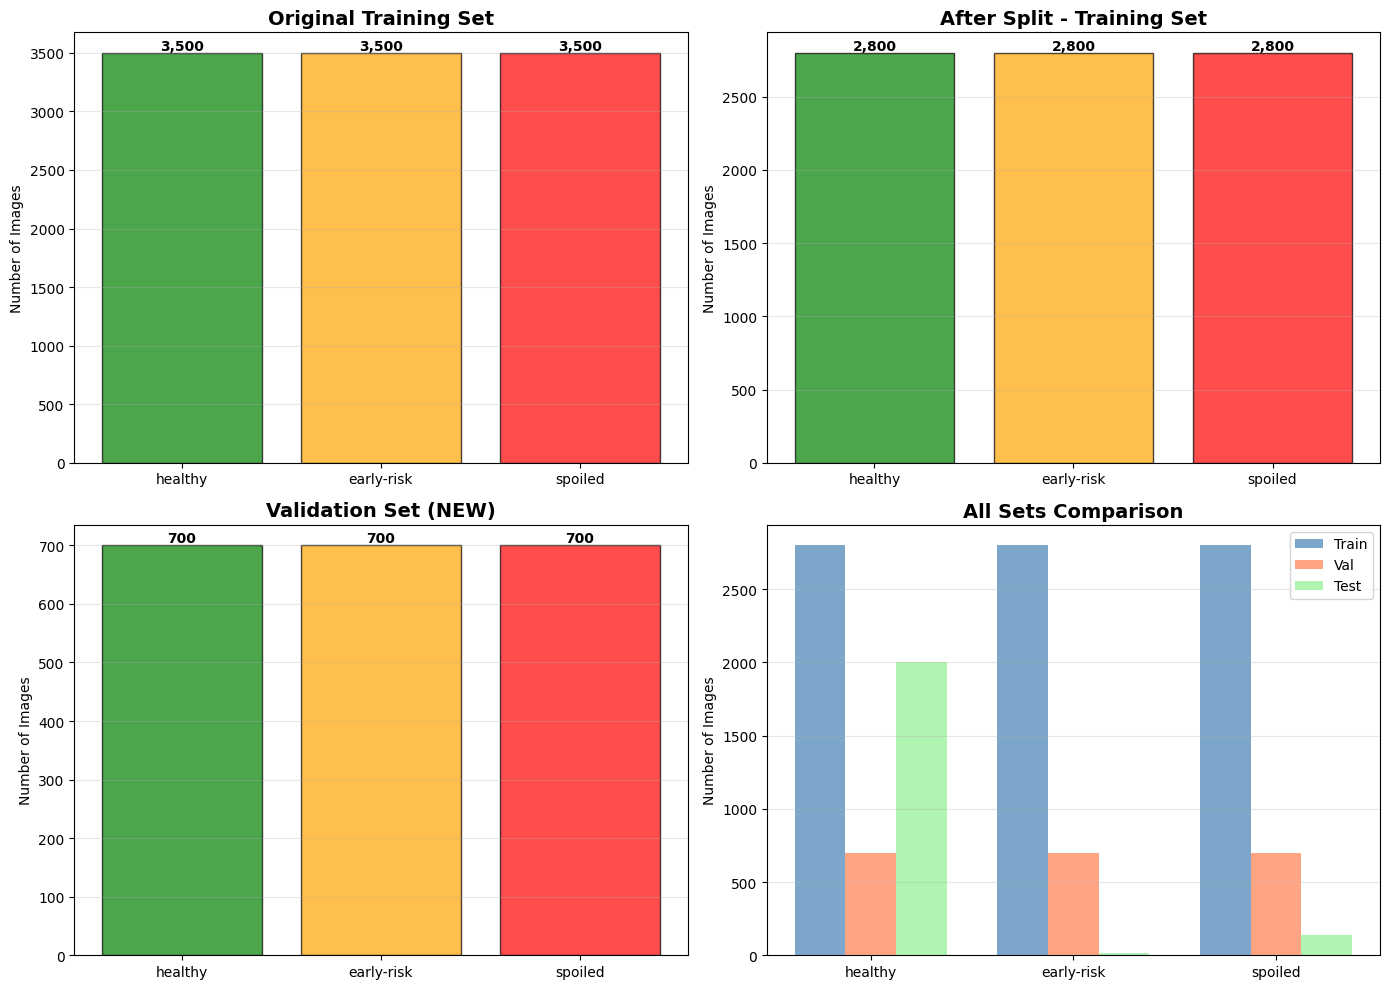

In [11]:
print("\n" + "="*80)
print("STEP 5: GENERATING VISUALIZATION")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

colors_map = {'healthy': 'green', 'early-risk': 'orange', 'spoiled': 'red'}

# 1. Original Training Set
ax = axes[0, 0]
counts = [stats_before[c] for c in categories]
bars = ax.bar(categories, counts, color=[colors_map[c] for c in categories],
              alpha=0.7, edgecolor='black')
ax.set_title('Original Training Set', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Images')
ax.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
           f'{int(height):,}', ha='center', va='bottom', fontweight='bold')

# 2. After Split - Training
ax = axes[0, 1]
train_counts = [stats_after['train'][c] for c in categories]
bars = ax.bar(categories, train_counts, color=[colors_map[c] for c in categories],
              alpha=0.7, edgecolor='black')
ax.set_title('After Split - Training Set', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Images')
ax.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
           f'{int(height):,}', ha='center', va='bottom', fontweight='bold')

# 3. Validation Set (NEW)
ax = axes[1, 0]
val_counts = [stats_after['val'][c] for c in categories]
bars = ax.bar(categories, val_counts, color=[colors_map[c] for c in categories],
              alpha=0.7, edgecolor='black')
ax.set_title('Validation Set (NEW)', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Images')
ax.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
           f'{int(height):,}', ha='center', va='bottom', fontweight='bold')

# 4. All Sets Comparison
ax = axes[1, 1]
x = np.arange(len(categories))
width = 0.25

bars1 = ax.bar(x - width, train_counts, width, label='Train',
               color='steelblue', alpha=0.7)
bars2 = ax.bar(x, val_counts, width, label='Val',
               color='coral', alpha=0.7)
bars3 = ax.bar(x + width, [stats_after['test'][c] for c in categories], width,
               label='Test', color='lightgreen', alpha=0.7)

ax.set_title('All Sets Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Images')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

# Save figure
viz_path = dataset_root / 'validation_split_visualization.png'
plt.savefig(viz_path, dpi=300, bbox_inches='tight')
print(f"\n✅ Visualization saved: {viz_path}")
plt.show()


In [ ]:
print("\n" + "="*80)
print("STEP 6: SAVING SUMMARY FILES")
print("="*80)

# Save text summary
summary_lines = [
    "="*80,
    "RICE MOLD DETECTION - VALIDATION SET CREATION SUMMARY",
    "="*80,
    f"\nGenerated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
    f"Dataset Root: {dataset_root}",
    f"Validation Ratio: {VAL_RATIO*100:.1f}% of training data",
    f"Random Seed: {RANDOM_SEED}",
    "\n" + "-"*80,
    "\nORIGINAL TRAINING SET:",
]

for category in categories:
    count = stats_before[category]
    summary_lines.append(f"  {category:15s}: {count:6,d} images")
summary_lines.append(f"  {'TOTAL':15s}: {total_before:6,d} images")

summary_lines.extend([
    "\n" + "-"*80,
    "\nAFTER SPLIT:",
    "\nTRAINING SET:",
])

for category in categories:
    count = stats_after['train'][category]
    percentage = (count / total_before * 100) if total_before > 0 else 0
    summary_lines.append(f"  {category:15s}: {count:6,d} images ({percentage:5.1f}% of original)")
summary_lines.append(f"  {'TOTAL':15s}: {train_total:6,d} images")

summary_lines.extend([
    "\nVALIDATION SET (NEW):",
])

for category in categories:
    count = stats_after['val'][category]
    percentage = (count / total_before * 100) if total_before > 0 else 0
    summary_lines.append(f"  {category:15s}: {count:6,d} images ({percentage:5.1f}% of original)")
summary_lines.append(f"  {'TOTAL':15s}: {val_total:6,d} images")

summary_lines.extend([
    "\nTEST SET (UNCHANGED):",
])

for category in categories:
    count = stats_after['test'][category]
    summary_lines.append(f"  {category:15s}: {count:6,d} images")
summary_lines.append(f"  {'TOTAL':15s}: {test_total:6,d} images")

summary_lines.extend([
    "\n" + "-"*80,
    "\nFINAL DISTRIBUTION:",
    f"  Training:   {train_total:6,d} images ({train_pct:5.1f}%)",
    f"  Validation: {val_total:6,d} images ({val_pct:5.1f}%)",
    f"  Test:       {test_total:6,d} images ({test_pct:5.1f}%)",
    f"  {'TOTAL':11s}: {grand_total:6,d} images",
    "\n" + "="*80,
])

summary_text = "\n".join(summary_lines)

summary_file = dataset_root / 'validation_split_summary.txt'
with open(summary_file, 'w') as f:
    f.write(summary_text)

print(f"✅ Summary saved: {summary_file}")


# Save JSON summary
import json

json_summary = {
    'timestamp': datetime.now().isoformat(),
    'dataset_root': str(dataset_root),
    'val_ratio': VAL_RATIO,
    'random_seed': RANDOM_SEED,
    'original_train': {
        'total': total_before,
        'healthy': stats_before['healthy'],
        'early_risk': stats_before['early-risk'],
        'spoiled': stats_before['spoiled']
    },
    'after_split': {
        'train': {
            'total': train_total,
            'healthy': stats_after['train']['healthy'],
            'early_risk': stats_after['train']['early-risk'],
            'spoiled': stats_after['train']['spoiled']
        },
        'val': {
            'total': val_total,
            'healthy': stats_after['val']['healthy'],
            'early_risk': stats_after['val']['early-risk'],
            'spoiled': stats_after['val']['spoiled']
        },
        'test': {
            'total': test_total,
            'healthy': stats_after['test']['healthy'],
            'early_risk': stats_after['test']['early-risk'],
            'spoiled': stats_after['test']['spoiled']
        }
    },
    'final_distribution': {
        'train_pct': round(train_pct, 2),
        'val_pct': round(val_pct, 2),
        'test_pct': round(test_pct, 2)
    }
}

json_file = dataset_root / 'validation_split_summary.json'
with open(json_file, 'w') as f:
    json.dump(json_summary, f, indent=2)

print(f"✅ JSON summary saved: {json_file}")


STEP 6: SAVING SUMMARY FILES
✅ Summary saved: D:\Research\rice\balanced_augmented_dataset\validation_split_summary.txt
✅ JSON summary saved: D:\Research\rice\balanced_augmented_dataset\validation_split_summary.json


: 